In [2]:
%matplotlib inline

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")          # save plots to files (no window needed)
import matplotlib.pyplot as plt
 

OUT_DIR = "eda_plots"
os.makedirs(OUT_DIR, exist_ok=True)


df = pd.read_csv("/Users/siddharth/Downloads/Steel_industry_data.csv")
df.columns = [c.strip() for c in df.columns]
 
RENAME = {
    "Usage_kWh": "kwh",
    "Lagging_Current_Reactive.Power_kVarh": "q_lag",
    "Leading_Current_Reactive_Power_kVarh": "q_lead",
    "CO2(tCO2)": "co2",
    "Lagging_Current_Power_Factor": "pf_lag",
    "Leading_Current_Power_Factor": "pf_lead",
    "NSM": "nsm",
    "WeekStatus": "week",
    "Day_of_week": "dow",
    "Load_Type": "load",
}
missing = [c for c in RENAME if c not in df.columns]
if missing:
    raise SystemExit(f"These columns were not found in your CSV: {missing}\n"
                     f"Columns in your file: {list(df.columns)}")
df = df.rename(columns=RENAME)
df["date"] = pd.to_datetime(df["date"], dayfirst=True)   # format is dd/mm/yyyy HH:MM
df = df.sort_values("date").reset_index(drop=True)
df["hour"] = df["date"].dt.hour
df["month"] = df["date"].dt.month
 

In [4]:
# ------------------------------------------------------------------ 2. BASIC INFO
print("=" * 70)
print("SHAPE:", df.shape)
print("\nTIME RANGE:", df["date"].min(), "->", df["date"].max())
print("\nDATA TYPES:\n", df.dtypes)
print("\nMISSING VALUES:\n", df.isna().sum())
print("\nDUPLICATE ROWS:", df.duplicated().sum())
 
steps = df["date"].diff().dropna().value_counts().head(3)
print("\nMOST COMMON TIME STEPS (should be 15 minutes):\n", steps)
 
num_cols = ["kwh", "q_lag", "q_lead", "co2", "pf_lag", "pf_lead", "nsm"]
print("\nDESCRIPTIVE STATISTICS:\n", df[num_cols].describe().T.round(3))
 
print("\nCATEGORY COUNTS:")
for c in ["week", "dow", "load"]:
    print(f"\n{c}:\n{df[c].value_counts()}")
 
print("\nMEAN VALUES BY LOAD TYPE:")
print(df.groupby("load")[["kwh", "q_lag", "co2", "pf_lag"]].mean().round(3))

SHAPE: (35040, 13)

TIME RANGE: 2018-01-01 00:00:00 -> 2018-12-31 23:45:00

DATA TYPES:
 date       datetime64[ns]
kwh               float64
q_lag             float64
q_lead            float64
co2               float64
pf_lag            float64
pf_lead           float64
nsm                 int64
week               object
dow                object
load               object
hour                int32
month               int32
dtype: object

MISSING VALUES:
 date       0
kwh        0
q_lag      0
q_lead     0
co2        0
pf_lag     0
pf_lead    0
nsm        0
week       0
dow        0
load       0
hour       0
month      0
dtype: int64

DUPLICATE ROWS: 0

MOST COMMON TIME STEPS (should be 15 minutes):
 date
0 days 00:15:00    35039
Name: count, dtype: int64

DESCRIPTIVE STATISTICS:
            count       mean        std  min       25%       50%        75%  \
kwh      35040.0     27.387     33.444  0.0      3.20      4.57     51.238   
q_lag    35040.0     13.035     16.306  0.0      2.30

In [5]:
# ------------------------------------------------------------------ 3. CORRELATIONS
corr = df[num_cols].corr()
print("\nCORRELATION MATRIX:\n", corr.round(3))
print("\n>>> corr(kWh, CO2) =", round(df["kwh"].corr(df["co2"]), 4),
      "(if ~1, CO2 is just energy in disguise -> report it, don't optimise it)")


CORRELATION MATRIX:
            kwh  q_lag  q_lead    co2  pf_lag  pf_lead    nsm
kwh      1.000  0.896  -0.325  0.988   0.386    0.354  0.235
q_lag    0.896  1.000  -0.405  0.887   0.145    0.408  0.083
q_lead  -0.325 -0.405   1.000 -0.333   0.527   -0.944  0.372
co2      0.988  0.887  -0.333  1.000   0.380    0.360  0.232
pf_lag   0.386  0.145   0.527  0.380   1.000   -0.520  0.565
pf_lead  0.354  0.408  -0.944  0.360  -0.520    1.000 -0.361
nsm      0.235  0.083   0.372  0.232   0.565   -0.361  1.000

>>> corr(kWh, CO2) = 0.9882 (if ~1, CO2 is just energy in disguise -> report it, don't optimise it)


In [6]:
# ------------------------------------------------------------------ 4. OUTLIERS (IQR rule)
print("\nOUTLIERS (IQR rule):")
for c in ["kwh", "q_lag", "co2"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    print(f"  {c}: {n_out} values ({100 * n_out / len(df):.2f}%)")


OUTLIERS (IQR rule):
  kwh: 328 values (0.94%)
  q_lag: 1059 values (3.02%)
  co2: 437 values (1.25%)


In [7]:
# ------------------------------------------------------------------ 5. COMPLETE DAYS
per_day = df.groupby(df["date"].dt.date).size()
print("\nDAYS WITH EXACTLY 96 READINGS:", (per_day == 96).sum(), "of", len(per_day))


DAYS WITH EXACTLY 96 READINGS: 365 of 365


In [8]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

In [9]:
# 5.1 first two weeks
first = df[df["date"] < df["date"].min() + pd.Timedelta(days=14)]
plt.figure(figsize=(13, 4))
plt.plot(first["date"], first["kwh"], lw=0.8)
plt.title("Energy use (kWh per 15 min) - first 14 days")
plt.ylabel("kWh"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/01_first_two_weeks.png", dpi=130); plt.show()


/var/folders/75/6l015n052l5_gpg_g84mtjzc0000gn/T/ipykernel_16966/381963679.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.savefig(f"{OUT_DIR}/01_first_two_weeks.png", dpi=130); plt.show()


In [10]:
# 6.2 average daily profile: weekday vs weekend
prof = df.groupby(["week", "hour"])["kwh"].mean().unstack(0)
prof.plot(figsize=(9, 4), marker="o")
plt.title("Average energy by hour of day"); plt.ylabel("kWh per 15 min")
plt.xlabel("Hour"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/02_hourly_profile.png", dpi=130); plt.close()


In [11]:
# 6.3 load-type counts and energy by load type
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["load"].value_counts().plot.bar(ax=ax[0], title="Number of readings per load type")
df.boxplot(column="kwh", by="load", ax=ax[1]); ax[1].set_title("kWh by load type")
plt.suptitle(""); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/03_load_types.png", dpi=130); plt.close()

In [12]:
# 6.4 monthly total energy
df.groupby("month")["kwh"].sum().plot.bar(figsize=(8, 4), title="Total energy per month (kWh)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/04_monthly_energy.png", dpi=130); plt.close()

In [13]:
# 6.5 CO2 vs kWh
plt.figure(figsize=(5, 5))
plt.scatter(df["kwh"], df["co2"], s=2, alpha=0.3)
plt.xlabel("kWh"); plt.ylabel("CO2 (tCO2)"); plt.title("CO2 vs energy")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/05_co2_vs_kwh.png", dpi=130); plt.close()

In [14]:
# 6.6 power factor distribution by load type
plt.figure(figsize=(8, 4))
for name, g in df.groupby("load"):
    plt.hist(g["pf_lag"], bins=50, alpha=0.5, label=name)
plt.legend(); plt.title("Lagging power factor by load type"); plt.xlabel("%")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/06_pf_distribution.png", dpi=130); plt.close()

In [15]:
# 6.7 correlation heatmap (matplotlib only)
plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(num_cols)), num_cols, rotation=45)
plt.yticks(range(len(num_cols)), num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(); plt.title("Correlation matrix"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/07_correlation.png", dpi=130); plt.close()

In [16]:
# 6.8 daily peak demand (max 15-min kWh per day) over the year
daily = df.groupby(df["date"].dt.date)["kwh"].agg(["sum", "max"])
daily.plot(subplots=True, figsize=(12, 5), title=["Daily total kWh", "Daily peak kWh (15 min)"], legend=False)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/08_daily_total_and_peak.png", dpi=130); plt.close()

In [17]:

print(f"\nDone. Plots saved in the folder '{OUT_DIR}'.")


Done. Plots saved in the folder 'eda_plots'.


In [18]:
import subprocess
subprocess.run(["open", os.path.abspath("eda_plots")])

CompletedProcess(args=['open', '/Users/siddharth/eda_plots'], returncode=0)

In [21]:
eda = pd.read_csv("/Users/siddharth/Downloads/Steel_industry_data.csv")
eda.columns = [c.strip() for c in eda.columns]
eda = eda.rename(columns={"Usage_kWh": "kwh", "Lagging_Current_Reactive.Power_kVarh": "q_lag",
                          "Leading_Current_Reactive_Power_kVarh": "q_lead", "CO2(tCO2)": "co2",
                          "Lagging_Current_Power_Factor": "pf_lag", "Leading_Current_Power_Factor": "pf_lead",
                          "NSM": "nsm", "WeekStatus": "week", "Day_of_week": "dow", "Load_Type": "load"})
eda["date"] = pd.to_datetime(eda["date"], dayfirst=True)
eda = eda.sort_values("date").reset_index(drop=True)
eda["hour"] = eda["date"].dt.hour
eda["month"] = eda["date"].dt.month
print("Full year:", eda.shape)

Full year: (35040, 13)


In [24]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
plt.switch_backend("module://matplotlib_inline.backend_inline")
print(matplotlib.get_backend())

module://matplotlib_inline.backend_inline


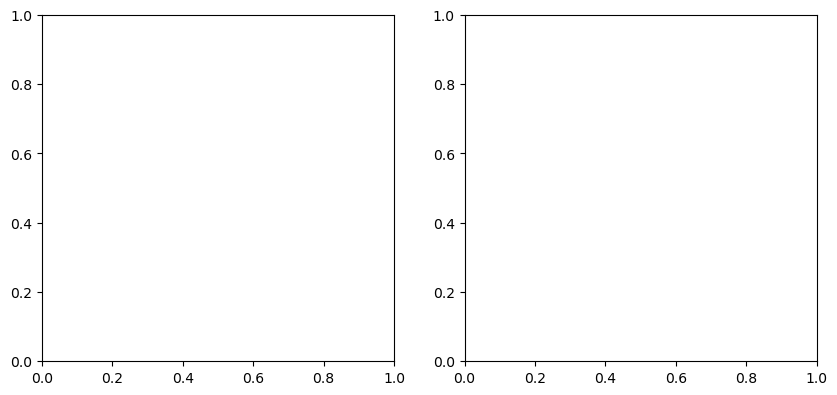

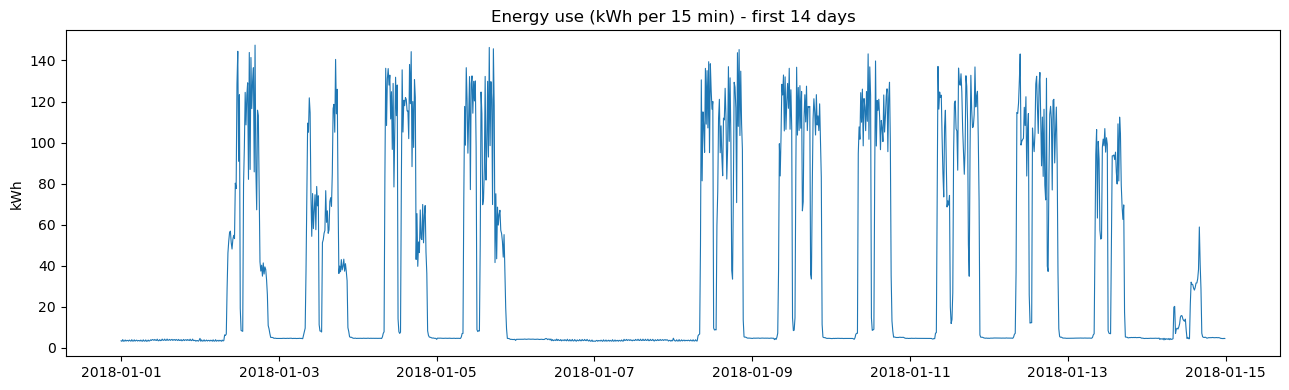

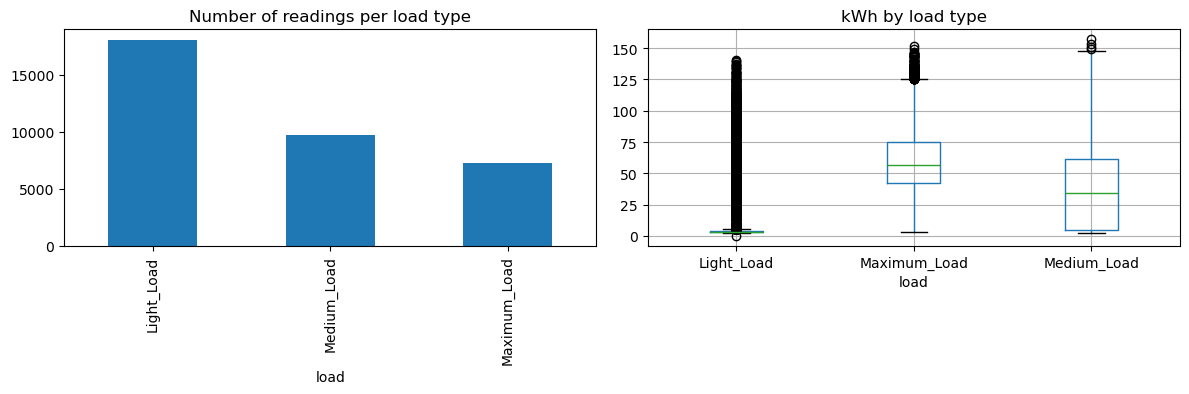

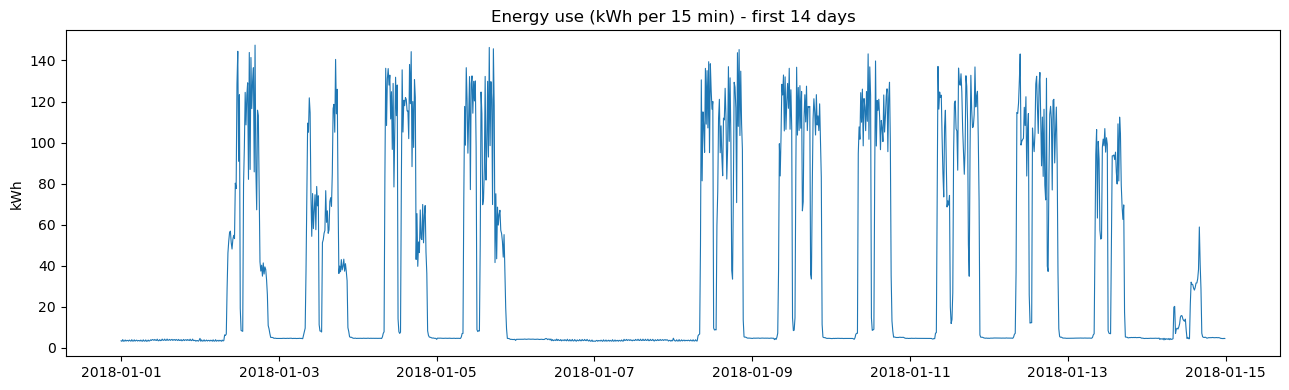

In [25]:
first = eda[eda["date"] < eda["date"].min() + pd.Timedelta(days=14)]
plt.figure(figsize=(13, 4))
plt.plot(first["date"], first["kwh"], lw=0.8)
plt.title("Energy use (kWh per 15 min) - first 14 days"); plt.ylabel("kWh")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_5_01_first_two_weeks.png", dpi=130); plt.show()

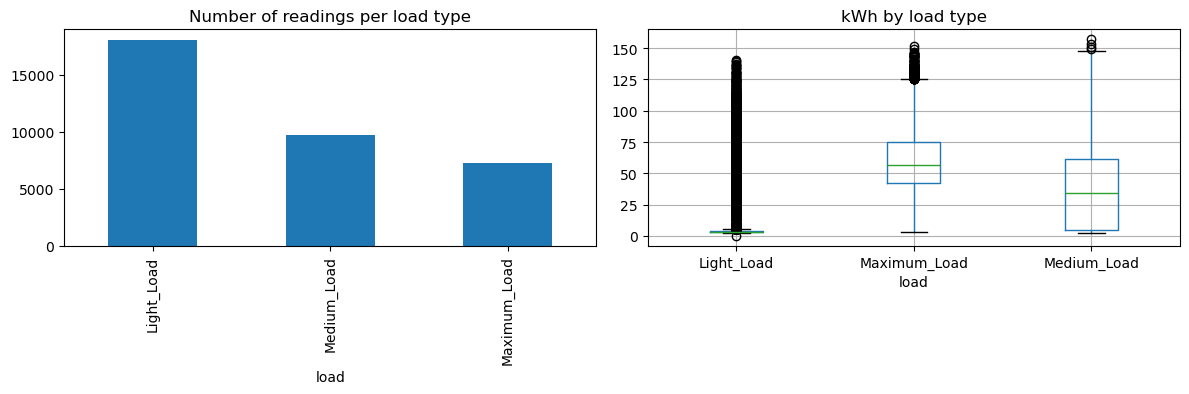

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
eda["load"].value_counts().plot.bar(ax=ax[0], title="Number of readings per load type")
eda.boxplot(column="kwh", by="load", ax=ax[1]); ax[1].set_title("kWh by load type")
plt.suptitle(""); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_5_02_load_types.png", dpi=130); plt.show()

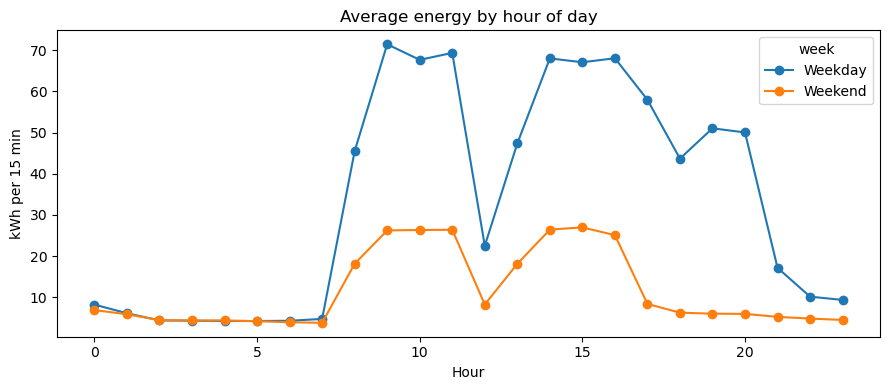

In [27]:
eda.groupby(["week", "hour"])["kwh"].mean().unstack(0).plot(figsize=(9, 4), marker="o")
plt.title("Average energy by hour of day"); plt.ylabel("kWh per 15 min"); plt.xlabel("Hour")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_5_03_hourly_profile.png", dpi=130); plt.show()

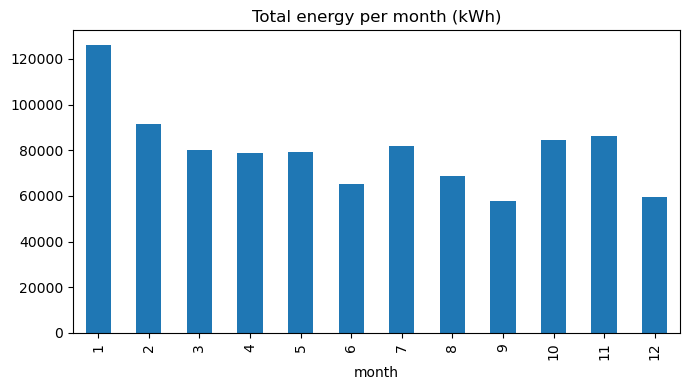

In [29]:
eda.groupby("month")["kwh"].sum().plot.bar(figsize=(7, 4), title="Total energy per month (kWh)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_5_04_monthly_energy.png", dpi=130); plt.show()

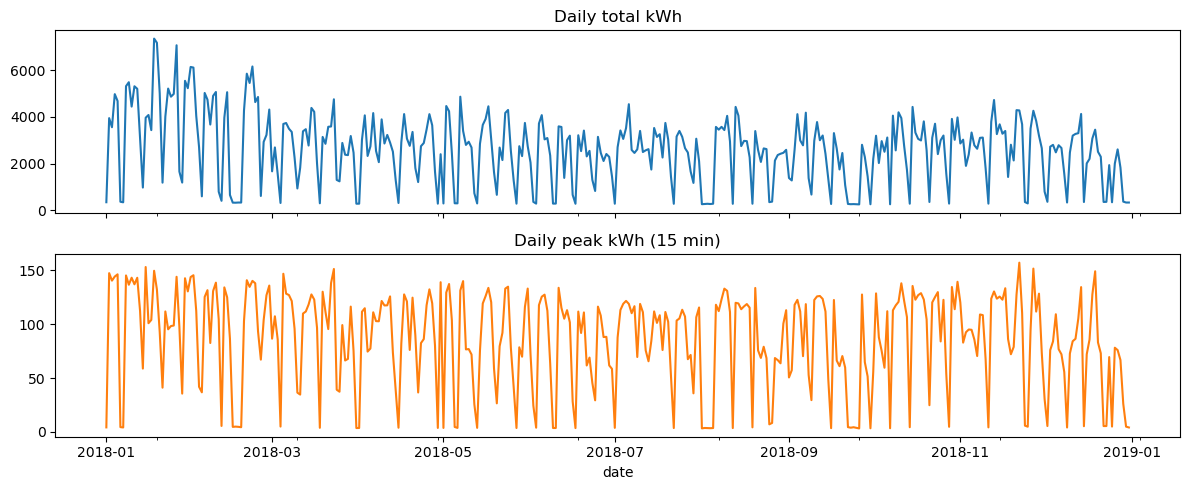

In [30]:
daily = eda.groupby(eda["date"].dt.date)["kwh"].agg(["sum", "max"])
daily.plot(subplots=True, figsize=(12, 5), title=["Daily total kWh", "Daily peak kWh (15 min)"], legend=False)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_5_05_daily_total_and_peak.png", dpi=130); plt.show()

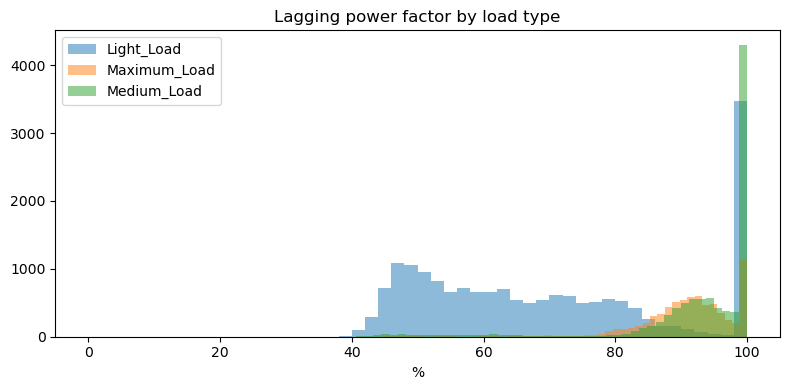

In [31]:
plt.figure(figsize=(8, 4))
for name, g in eda.groupby("load"):
    plt.hist(g["pf_lag"], bins=50, alpha=0.5, label=name)
plt.legend(); plt.title("Lagging power factor by load type"); plt.xlabel("%")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_5_06_pf_by_load.png", dpi=130); plt.show()

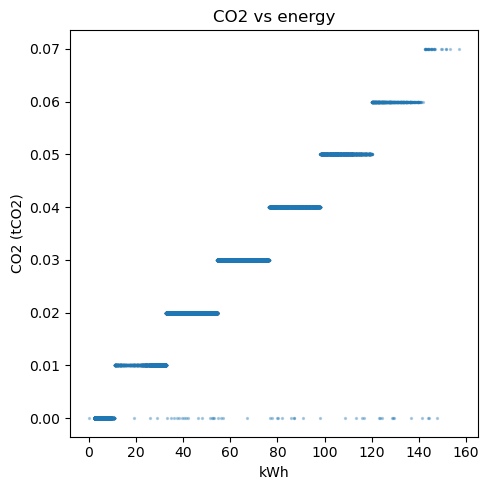

corr(kWh, CO2) = 0.988


In [32]:
plt.figure(figsize=(5, 5))
plt.scatter(eda["kwh"], eda["co2"], s=2, alpha=0.3)
plt.xlabel("kWh"); plt.ylabel("CO2 (tCO2)"); plt.title("CO2 vs energy")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_5_07_co2_vs_kwh.png", dpi=130); plt.show()
print("corr(kWh, CO2) =", round(eda["kwh"].corr(eda["co2"]), 3))

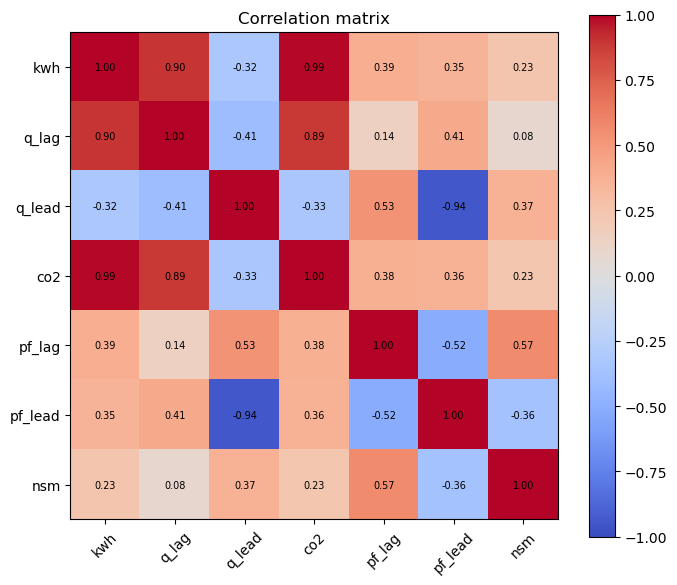

In [33]:
cols = ["kwh", "q_lag", "q_lead", "co2", "pf_lag", "pf_lead", "nsm"]
cm = eda[cols].corr()
plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(cols)), cols, rotation=45); plt.yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        plt.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(); plt.title("Correlation matrix"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_5_08_correlation.png", dpi=130); plt.show()